# Web Scraping and Text Analysis: Books to Scrape

**Project topic:** Book discovery and reader appeal  
**Data source:** [Books to Scrape](https://books.toscrape.com/), a public practice website for web scraping  
**Workflow:** collect at least 50 product pages with Requests and BeautifulSoup, clean the text, apply VADER sentiment and TF-IDF relevance, generate extractive summaries, calculate directional importance, and export the results.

This notebook is self-contained: it includes the live web-scraping process and the text-analysis workflow. It does not require a previously generated CSV to begin. The scraping section saves `scraped_books_raw.csv`; later sections work directly with the data collected in this run.

## 1. Why BeautifulSoup instead of Scrapy?

This project collects a small, fixed sample of 50 product pages. **Requests + BeautifulSoup** is a straightforward choice for this scope: Requests downloads each page, while BeautifulSoup parses its HTML and extracts the required fields.

**Scrapy** is a stronger choice for larger production crawls because it provides a full crawling framework, including scheduling, concurrency, pipelines, and built-in retry controls. For this bounded classroom exercise, BeautifulSoup is easier to explain and demonstrate in a Jupyter notebook.

The notebook does not claim a measured performance comparison between the two libraries. A fair benchmark would require implementing equivalent crawlers and testing them under the same network and machine conditions.

## 2. Environment and dependencies

The project is designed to run in **Jupyter Notebook through Anaconda**. The next cell installs the required libraries into the active notebook kernel.

In [ ]:
%pip install -q requests beautifulsoup4 pandas numpy scikit-learn vaderSentiment matplotlib

In [53]:
import re
import time
import random
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

pd.set_option("display.max_colwidth", 120)

In [55]:
from pathlib import Path

# Keep generated datasets and analysis outputs together in this folder.
OUTPUT_DIR = Path.cwd() / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())

Output directory: C:\Users\USER\Documents\aDouglas\3\Special Topics\assignment 2\ass 2\Final\output


## 3. Web scraping: collect 50 product pages

The scraper first visits the catalogue pages and collects product-page links. It then visits each unique product page and extracts:

- Product URL
- Book title
- Price
- Star rating
- Category
- Product description

A short delay is used between requests. The User-Agent header is selected from a small list to identify the client in a conventional browser-like way. This is **not** intended to bypass blocks, rate limits, or access controls. If the website denies access or asks the crawler to stop, stop the crawl and follow its rules.

The target is a practice website. Before scraping any other website, check its terms, robots.txt, and crawl policy.

In [58]:
BASE_URL = "https://books.toscrape.com/"
TARGET_PAGES = 50
REQUEST_DELAY_SECONDS = (0.8, 1.5)
TIMEOUT_SECONDS = 20

USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/124.0 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 13_6) AppleWebKit/605.1.15 Version/17.0 Safari/605.1.15",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 Chrome/123.0 Safari/537.36",
]

session = requests.Session()

def get_soup(url):
    headers = {"User-Agent": random.choice(USER_AGENTS)}
    response = session.get(url, headers=headers, timeout=TIMEOUT_SECONDS)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")

def polite_pause():
    time.sleep(random.uniform(*REQUEST_DELAY_SECONDS))

### 3.1 Discover product-page URLs

Catalogue pages contain multiple book links and a `next` link for pagination. The loop follows catalogue pages until it has collected at least 50 product links or there are no more catalogue pages.

In [61]:
product_urls = []
catalogue_url = BASE_URL
catalogue_pages_visited = 0

while catalogue_url and len(set(product_urls)) < TARGET_PAGES:
    catalogue_soup = get_soup(catalogue_url)
    catalogue_pages_visited += 1

    for link in catalogue_soup.select("article.product_pod h3 a"):
        product_urls.append(urljoin(catalogue_url, link.get("href")))

    next_link = catalogue_soup.select_one("li.next a")
    catalogue_url = urljoin(catalogue_url, next_link.get("href")) if next_link else None

    if catalogue_url:
        polite_pause()

product_urls = list(dict.fromkeys(product_urls))[:TARGET_PAGES]

print("Catalogue pages visited:", catalogue_pages_visited)
print("Unique product URLs collected:", len(product_urls))
if len(product_urls) < TARGET_PAGES:
    print("Notice: fewer than 50 product links were found.")

Catalogue pages visited: 3
Unique product URLs collected: 50


### 3.2 Extract information from each product page

The scraper uses CSS selectors to locate the book title, price, rating, description, and category. Missing elements are stored as empty strings so that one incomplete page does not stop the whole collection.

In [63]:
def extract_product(url):
    soup = get_soup(url)

    title_node = soup.select_one("div.product_main h1")
    price_node = soup.select_one("div.product_main p.price_color")
    rating_node = soup.select_one("div.product_main p.star-rating")
    description_node = soup.select_one("#product_description + p")
    category_node = soup.select_one("ul.breadcrumb li:nth-of-type(3) a")

    rating = ""
    if rating_node:
        rating_classes = [c for c in rating_node.get("class", []) if c != "star-rating"]
        rating = rating_classes[0] if rating_classes else ""

    return {
        "url": url,
        "title": title_node.get_text(" ", strip=True) if title_node else "",
        "price": price_node.get_text(" ", strip=True) if price_node else "",
        "rating": rating,
        "category": category_node.get_text(" ", strip=True) if category_node else "",
        "description": description_node.get_text(" ", strip=True) if description_node else "",
    }

scraped_rows = []
failed_urls = []

for number, url in enumerate(product_urls, start=1):
    try:
        scraped_rows.append(extract_product(url))
        print(f"Scraped {number}/{len(product_urls)}")
    except requests.RequestException as error:
        failed_urls.append({"url": url, "error": str(error)})
        print(f"Could not retrieve {url}: {error}")
    except Exception as error:
        failed_urls.append({"url": url, "error": str(error)})
        print(f"Could not parse {url}: {error}")

    if number < len(product_urls):
        polite_pause()

raw_df = pd.DataFrame(scraped_rows)
raw_df = raw_df.drop_duplicates(subset="url").reset_index(drop=True)

RAW_OUTPUT = "scraped_books_raw.csv"
raw_df.to_csv(OUTPUT_DIR / RAW_OUTPUT, index=False, encoding="utf-8-sig")

print("\nScraping complete.")
print("Unique product pages scraped:", len(raw_df))
print("Failed pages:", len(failed_urls))
print("Saved raw data to:", RAW_OUTPUT)
display(raw_df.head())

Scraped 1/50
Scraped 2/50
Scraped 3/50
Scraped 4/50
Scraped 5/50
Scraped 6/50
Scraped 7/50
Scraped 8/50
Scraped 9/50
Scraped 10/50
Scraped 11/50
Scraped 12/50
Scraped 13/50
Scraped 14/50
Scraped 15/50
Scraped 16/50
Scraped 17/50
Scraped 18/50
Scraped 19/50
Scraped 20/50
Scraped 21/50
Scraped 22/50
Scraped 23/50
Scraped 24/50
Scraped 25/50
Scraped 26/50
Scraped 27/50
Scraped 28/50
Scraped 29/50
Scraped 30/50
Scraped 31/50
Scraped 32/50
Scraped 33/50
Scraped 34/50
Scraped 35/50
Scraped 36/50
Scraped 37/50
Scraped 38/50
Scraped 39/50
Scraped 40/50
Scraped 41/50
Scraped 42/50
Scraped 43/50
Scraped 44/50
Scraped 45/50
Scraped 46/50
Scraped 47/50
Scraped 48/50
Scraped 49/50
Scraped 50/50

Scraping complete.
Unique product pages scraped: 50
Failed pages: 0
Saved raw data to: scraped_books_raw.csv


,url,title,price,rating,category,description
0,https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html,A Light in the Attic,Â£51.77,Three,Poetry,It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from S...
1,https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html,Tipping the Velvet,Â£53.74,One,Historical Fiction,"""Erotic and absorbing...Written with starling power.""--""The New York Times Book Review "" Nan King, an oyster girl, i..."
2,https://books.toscrape.com/catalogue/soumission_998/index.html,Soumission,Â£50.10,One,Fiction,"Dans une France assez proche de la nÃ´tre, un homme sâengage dans la carriÃ¨re universitaire. Peu motivÃ© par lâ..."
3,https://books.toscrape.com/catalogue/sharp-objects_997/index.html,Sharp Objects,Â£47.82,Four,Mystery,"WICKED above her hipbone, GIRL across her heart Words are like a road map to reporter Camille Preakerâs troubled p..."
4,https://books.toscrape.com/catalogue/sapiens-a-brief-history-of-humankind_996/index.html,Sapiens: A Brief History of Humankind,Â£54.23,Five,History,From a renowned historian comes a groundbreaking narrative of humanityâs creation and evolutionâa #1 internation...


### 3.3 Validate the collected dataset

The assignment requires at least 50 pages. This check confirms how many unique product pages were collected and identifies missing descriptions. If fewer than 50 pages were collected, check the connection and rerun the scraping section when access is available.

In [65]:
print("Unique product pages:", raw_df["url"].nunique())
print("Missing descriptions:", raw_df["description"].fillna("").str.strip().eq("").sum())

if raw_df["url"].nunique() < TARGET_PAGES:
    print("WARNING: The dataset contains fewer than 50 unique pages.")
else:
    print("The dataset meets the 50-page collection target.")

display(raw_df[["title", "category", "price", "rating", "url"]].head())

Unique product pages: 50
Missing descriptions: 0
The dataset meets the 50-page collection target.


,title,category,price,rating,url
0,A Light in the Attic,Poetry,Â£51.77,Three,https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Historical Fiction,Â£53.74,One,https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html
2,Soumission,Fiction,Â£50.10,One,https://books.toscrape.com/catalogue/soumission_998/index.html
3,Sharp Objects,Mystery,Â£47.82,Four,https://books.toscrape.com/catalogue/sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,History,Â£54.23,Five,https://books.toscrape.com/catalogue/sapiens-a-brief-history-of-humankind_996/index.html


## 4. Text cleaning and preparation

The following steps repair common text-encoding artefacts, handle missing values, remove duplicate URLs, and combine each title and description into one text field for analysis.

In [67]:
def repair_text(value):
    if pd.isna(value):
        return ""
    text = str(value)

    # Repair common UTF-8 text that was decoded using Windows-1252.
    for _ in range(2):
        if any(marker in text for marker in ["Ã", "Â", "â€", "â€™", "â€œ", "â€”", "â"]):
            try:
                text = text.encode("cp1252").decode("utf-8")
            except (UnicodeEncodeError, UnicodeDecodeError):
                break

    text = text.replace("\\xa0", " ").replace("\\u200b", " ")
    return re.sub(r"\\s+", " ", text).strip()

df = raw_df.copy()

for column in ["title", "description", "category", "price", "rating", "url"]:
    if column in df.columns:
        df[column] = df[column].apply(repair_text)

df["category"] = df["category"].replace("", "Uncategorized")
df["text"] = (df["title"] + ". " + df["description"]).str.strip()
df = df.drop_duplicates(subset="url").reset_index(drop=True)

print("Rows available for analysis:", len(df))
print("Missing descriptions:", df["description"].eq("").sum())
display(df[["title", "category", "price", "rating"]].head())

Rows available for analysis: 50
Missing descriptions: 0


,title,category,price,rating
0,A Light in the Attic,Poetry,£51.77,Three
1,Tipping the Velvet,Historical Fiction,£53.74,One
2,Soumission,Fiction,£50.10,One
3,Sharp Objects,Mystery,£47.82,Four
4,Sapiens: A Brief History of Humankind,History,£54.23,Five


## 5. Algorithm 1 — VADER sentiment analysis

VADER (Valence Aware Dictionary and sEntiment Reasoner) estimates the sentiment expressed in a piece of text. Its compound score ranges from -1 (most negative) to +1 (most positive).

The commonly used thresholds are:

- Compound score ≥ 0.05: Positive
- Compound score ≤ -0.05: Negative
- Otherwise: Neutral

**Interpretation:** Books to Scrape contains product descriptions and promotional copy, not independent customer reviews. Therefore, the sentiment score describes the tone of the description, not the actual quality of the book or readers' opinions.

In [69]:
vader = SentimentIntensityAnalyzer()

df["sentiment_compound"] = df["text"].apply(
    lambda text: vader.polarity_scores(text)["compound"]
)

df["sentiment_label"] = df["sentiment_compound"].apply(
    lambda score: "Positive" if score >= 0.05
    else ("Negative" if score <= -0.05 else "Neutral")
)

display(
    df["sentiment_label"]
    .value_counts()
    .rename_axis("Sentiment")
    .to_frame("Number of pages")
)

,Number of pages
Sentiment,
Positive,42
Negative,7
Neutral,1


## 6. Algorithm 2 — TF-IDF topic relevance

TF-IDF (Term Frequency–Inverse Document Frequency) represents text using word and phrase weights. Cosine similarity compares each book's text with a topic description.

The topic is **book discovery and reader appeal**. It includes words related to books, genres, stories, authors, writing styles, themes, and audiences.

The raw cosine similarities are also converted into percentile scores from 0 to 100. These are relative rankings within this collected dataset: a score of 90 means the page ranks above roughly 90% of the pages in this sample. It does not mean 90% absolute relevance.

In [71]:
TOPIC = (
    "book discovery reader appeal genre story narrative characters themes author "
    "writing style audience literary fiction nonfiction poetry history romance "
    "mystery fantasy adventure biography children books"
)

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=1,
    max_df=0.95
)

document_matrix = vectorizer.fit_transform(df["text"])
topic_vector = vectorizer.transform([TOPIC])

df["topic_similarity_raw"] = cosine_similarity(
    document_matrix, topic_vector
).ravel()

df["relevance_score_100"] = (
    df["topic_similarity_raw"].rank(pct=True, method="average") * 100
).round(2)

display(
    df[["title", "topic_similarity_raw", "relevance_score_100"]]
    .sort_values("relevance_score_100", ascending=False)
    .head(10)
)

,title,topic_similarity_raw,relevance_score_100
17,Mesaerion: The Best Science Fiction Stories 1800-1849,0.067025,100.0
16,Olio,0.061457,98.0
7,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull",0.057325,96.0
25,Birdsong: A Story in Pictures,0.049308,94.0
28,Worlds Elsewhere: Journeys Around Shakespeareâs Globe,0.047981,92.0
4,Sapiens: A Brief History of Humankind,0.044561,90.0
36,Maude (1883-1993):She Grew Up with the country,0.040775,88.0
40,Slow States of Collapse: Poems,0.038291,86.0
27,Aladdin and His Wonderful Lamp,0.036780,84.0
20,In Her Wake,0.030425,82.0


## 7. Extractive text summaries

The summary function splits each description into sentences, scores sentences using their average TF-IDF term weights, and selects up to two informative sentences. The selected sentences are returned in their original order and limited to 60 words.

These are **extractive summaries**: they reuse sentences from the original description rather than generating new wording.

In [73]:
def split_sentences(text):
    parts = re.split(r'(?<=[.!?])\\s+(?=[A-Z0-9“"])', str(text))
    return [part.strip() for part in parts if len(part.strip()) > 25]

def make_summary(text, max_words=60):
    sentences = split_sentences(text)
    if not sentences:
        return str(text)[:300]

    sentence_matrix = vectorizer.transform(sentences)
    weight_sums = np.asarray(sentence_matrix.sum(axis=1)).ravel()
    term_counts = np.maximum(
        np.asarray((sentence_matrix != 0).sum(axis=1)).ravel(), 1
    )
    sentence_scores = weight_sums / term_counts

    ranked_indices = np.argsort(sentence_scores)[::-1]
    chosen_indices = []
    seen = set()

    for index in ranked_indices:
        normalized = re.sub(r"\\W+", " ", sentences[index].lower()).strip()
        if normalized and normalized not in seen:
            chosen_indices.append(int(index))
            seen.add(normalized)
        if len(chosen_indices) == 2:
            break

    chosen_indices.sort()
    summary = " ".join(sentences[index] for index in chosen_indices)
    words = summary.split()

    if len(words) > max_words:
        summary = " ".join(words[:max_words]).rstrip(" ,;:") + "…"

    return summary

df["summary"] = df["text"].apply(make_summary)
display(df[["title", "summary"]].head(10))

,title,summary
0,A Light in the Attic,A Light in the Attic. It's hard to imagine a world without A Light in the Attic. This now-classic collection of poet...
1,Tipping the Velvet,"Tipping the Velvet. ""Erotic and absorbing...Written with starling power.""--""The New York Times Book Review "" Nan Kin..."
2,Soumission,"Soumission. Dans une France assez proche de la nÃ´tre, un homme sâengage dans la carriÃ¨re universitaire. Peu moti..."
3,Sharp Objects,"Sharp Objects. WICKED above her hipbone, GIRL across her heart Words are like a road map to reporter Camille Preaker..."
4,Sapiens: A Brief History of Humankind,Sapiens: A Brief History of Humankind. From a renowned historian comes a groundbreaking narrative of humanityâs cr...
5,The Requiem Red,The Requiem Red. Patient Twenty-nine.A monster roams the halls of Soothing Hills Asylum. Three girls dead. 29 is end...
6,The Dirty Little Secrets of Getting Your Dream Job,The Dirty Little Secrets of Getting Your Dream Job. Drawing on his extensive experience evaluating applicants for hi...
7,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull","The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull. ""If you have a heart, if yo..."
8,The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics,The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics. For readers of Laura...
9,The Black Maria,"The Black Maria. Praise for Aracelis Girmay:""[Girmay's] every lossâshe calls them estrangementsâis a yearning fo..."


## 8. Directional importance score

The directional importance score combines the relative topic relevance with the VADER sentiment score:

**Directional Importance = Relevance Percentile × VADER Compound**

The result is approximately between -100 and +100. Positive values indicate positive language, while negative values indicate negative language, weighted by the page's relative topic relevance.

The accompanying category uses these rules:

- **Low relevance:** relevance percentile below 20, regardless of sentiment.
- **Positive:** relevance percentile ≥ 20 and VADER compound ≥ 0.05.
- **Negative:** relevance percentile ≥ 20 and VADER compound ≤ -0.05.
- **Neutral:** relevance percentile ≥ 20 and sentiment between -0.05 and +0.05.

The 20th-percentile cutoff is a practical choice for this sample, not a universal statistical threshold.

In [75]:
df["directional_importance"] = (
    df["relevance_score_100"] * df["sentiment_compound"]
).round(2)

df["importance_direction"] = np.where(
    df["relevance_score_100"] < 20,
    "Low relevance",
    np.where(
        df["sentiment_compound"] >= 0.05,
        "Positive",
        np.where(df["sentiment_compound"] <= -0.05, "Negative", "Neutral")
    )
)

## 9. Results: ranked pages and summaries

The results table combines the scraped book information with the two text algorithms, the extractive summary, and the directional importance score.

In [77]:
results = df[[
    "title", "category", "price", "rating", "summary",
    "sentiment_compound", "sentiment_label",
    "topic_similarity_raw", "relevance_score_100",
    "directional_importance", "importance_direction", "url"
]].sort_values(
    "directional_importance", ascending=False
).reset_index(drop=True)

display(results)

,title,category,price,rating,summary,sentiment_compound,sentiment_label,topic_similarity_raw,relevance_score_100,directional_importance,importance_direction,url
0,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull",Default,£17.93,Three,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull. ""If you have a heart, if yo...",0.9987,Positive,0.057325,96.0,95.88,Positive,https://books.toscrape.com/catalogue/the-coming-woman-a-novel-based-on-the-life-of-the-infamous-feminist-victoria-wo...
1,Worlds Elsewhere: Journeys Around Shakespeareâs Globe,Nonfiction,£40.30,Five,"Worlds Elsewhere: Journeys Around Shakespeareâs Globe. Anti-apartheid activist, Bollywood screenwriter, Nazi pin-u...",0.9940,Positive,0.047981,92.0,91.45,Positive,https://books.toscrape.com/catalogue/worlds-elsewhere-journeys-around-shakespeares-globe_972/index.html
2,Birdsong: A Story in Pictures,Childrens,£54.64,Three,Birdsong: A Story in Pictures. Bring the thrilling story of one red bird to life. When an innocent bird meets two cr...,0.9623,Positive,0.049308,94.0,90.46,Positive,https://books.toscrape.com/catalogue/birdsong-a-story-in-pictures_975/index.html
3,Mesaerion: The Best Science Fiction Stories 1800-1849,Science Fiction,£37.59,One,"Mesaerion: The Best Science Fiction Stories 1800-1849. Andrew Barger, award-winning author and engineer, has extensi...",0.8882,Positive,0.067025,100.0,88.82,Positive,https://books.toscrape.com/catalogue/mesaerion-the-best-science-fiction-stories-1800-1849_983/index.html
4,Sapiens: A Brief History of Humankind,History,£54.23,Five,Sapiens: A Brief History of Humankind. From a renowned historian comes a groundbreaking narrative of humanityâs cr...,0.9772,Positive,0.044561,90.0,87.95,Positive,https://books.toscrape.com/catalogue/sapiens-a-brief-history-of-humankind_996/index.html
5,Aladdin and His Wonderful Lamp,Default,£53.13,Three,"Aladdin and His Wonderful Lamp. Planning on seeing Aladdin the Disney musical? Read the classic story of ""Aladdin an...",0.9878,Positive,0.036780,84.0,82.98,Positive,https://books.toscrape.com/catalogue/aladdin-and-his-wonderful-lamp_973/index.html
6,The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics,Default,£22.60,Four,The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics. For readers of Laura...,0.9890,Positive,0.029336,80.0,79.12,Positive,https://books.toscrape.com/catalogue/the-boys-in-the-boat-nine-americans-and-their-epic-quest-for-gold-at-the-1936-b...
7,#HigherSelfie: Wake Up Your Life. Free Your Soul. Find Your Tribe.,Nonfiction,£23.11,Five,#HigherSelfie: Wake Up Your Life. Free Your Soul. Find Your Tribe.. There is a cosmic alarm clock going off around t...,0.9834,Positive,0.027548,78.0,76.71,Positive,https://books.toscrape.com/catalogue/higherselfie-wake-up-your-life-free-your-soul-find-your-tribe_957/index.html
8,Maude (1883-1993):She Grew Up with the country,Default,£18.02,Two,Maude (1883-1993):She Grew Up with the country. This new edition of Maude (1883-1993) has been updated by Mardo Will...,0.8625,Positive,0.040775,88.0,75.90,Positive,https://books.toscrape.com/catalogue/maude-1883-1993she-grew-up-with-the-country_964/index.html
9,Shakespeare's Sonnets,Poetry,£20.66,Four,Shakespeare's Sonnets. This book is an important and complete collection of the Sonnets of William Shakespeare. Most...,0.9927,Positive,0.027400,76.0,75.45,Positive,https://books.toscrape.com/catalogue/shakespeares-sonnets_989/index.html


## 10. Visualisation and overall findings

The charts show the distribution of directional classifications and the spread of relative relevance scores. The numerical summaries provide an overview of sentiment and relevance across the collected pages.

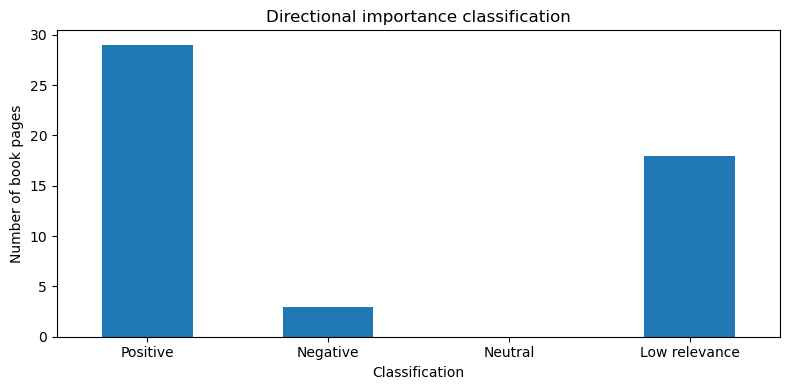

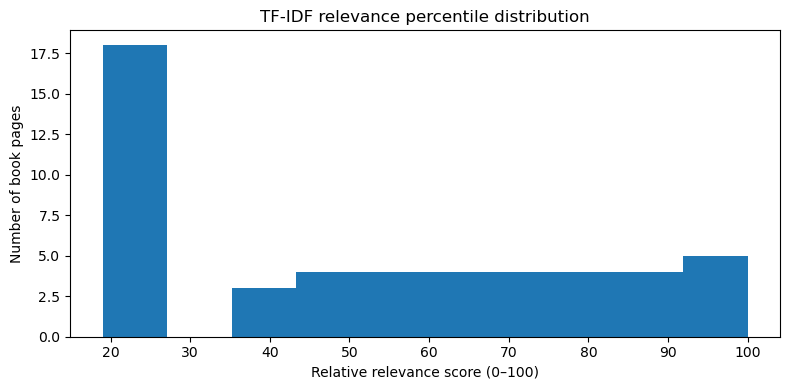

Pages analysed: 50
Mean VADER compound: 0.632
Mean relevance percentile: 51.0

Directional classification counts:


,Pages
importance_direction,
Positive,29
Low relevance,18
Negative,3


In [80]:
direction_order = ["Positive", "Negative", "Neutral", "Low relevance"]

fig, ax = plt.subplots(figsize=(8, 4))
df["importance_direction"].value_counts().reindex(
    direction_order, fill_value=0
).plot(kind="bar", ax=ax)
ax.set_title("Directional importance classification")
ax.set_xlabel("Classification")
ax.set_ylabel("Number of book pages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["relevance_score_100"], bins=10)
ax.set_title("TF-IDF relevance percentile distribution")
ax.set_xlabel("Relative relevance score (0–100)")
ax.set_ylabel("Number of book pages")
plt.tight_layout()
plt.show()

print("Pages analysed:", len(df))
print("Mean VADER compound:", round(df["sentiment_compound"].mean(), 3))
print("Mean relevance percentile:", round(df["relevance_score_100"].mean(), 2))
print("\nDirectional classification counts:")
display(df["importance_direction"].value_counts().to_frame("Pages"))

## 11. Export the project datasets

The notebook creates an `output/` folder in the current working directory and exports both the raw scraped records and the processed analysis results there. The raw file preserves the fields collected from the website; the results file contains the cleaned text, sentiment, relevance, summaries, and importance classifications. All generated CSV files are saved inside `output/`, keeping the project root tidy.

In [82]:
raw_df.to_csv(OUTPUT_DIR / "scraped_books_raw.csv", index=False, encoding="utf-8-sig")
df.to_csv(OUTPUT_DIR / "scraped_books_raw_cleaned.csv", index=False, encoding="utf-8-sig")
results.to_csv(OUTPUT_DIR / "scraped_text_analysis_results.csv", index=False, encoding="utf-8-sig")

print("Exported:")
print("- output/scraped_books_raw.csv")
print("- output/scraped_books_raw_cleaned.csv")
print("- output/scraped_text_analysis_results.csv")

Exported:
- output/scraped_books_raw.csv
- output/scraped_books_raw_cleaned.csv
- output/scraped_text_analysis_results.csv


## 12. Limitations and responsible interpretation

1. **Sentiment context:** VADER analyses promotional descriptions, not verified customer reviews or objective book quality.
2. **Lexical relevance:** TF-IDF measures word and phrase overlap. It does not fully understand meaning, context, or synonyms.
3. **Relative scores:** Relevance percentiles are calculated within this sample of pages and should not be compared directly with scores from unrelated datasets.
4. **Heuristic threshold:** The 20th-percentile low-relevance cutoff is an analytical choice made for this project.
5. **Extractive summaries:** Selected sentences may omit nuance or important details from a longer description.
6. **Website changes:** HTML structure can change, which may require updating the CSS selectors used by the scraper.
7. **Scraping etiquette:** Requests are spaced out, and the notebook should only be used where scraping is permitted. Do not use User-Agent changes or retries to evade access restrictions.

## 13. Conclusion

This project demonstrates an end-to-end text analytics workflow, beginning with the collection of at least 50 book product pages and continuing through cleaning, analysis, visualisation, and export. Requests and BeautifulSoup were used to retrieve and parse product information. VADER was applied to estimate the sentiment expressed in the descriptions, while TF-IDF and cosine similarity were used to rank pages by their lexical relevance to the book-discovery topic. Extractive summaries made the descriptions easier to review, and the directional importance score combined relevance and sentiment into one interpretable measure.

Together, the scraping and analysis stages provide a reproducible way to turn public product-page text into a structured dataset and a set of descriptive insights. The results should be interpreted as an analysis of the wording and topic overlap in the sampled descriptions, rather than as a measure of actual reader satisfaction or book quality.

## References

- Books to Scrape. https://books.toscrape.com/
- Beautiful Soup documentation. https://www.crummy.com/software/BeautifulSoup/bs4/doc/
- Requests documentation. https://requests.readthedocs.io/
- scikit-learn: TF-IDF Vectorizer. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- VADER Sentiment Analysis. https://github.com/cjhutto/vaderSentiment
- AI Engineering Hub repository reviewed for project structure and learning reference: https://github.com/patchy631/ai-engineering-hub